# Training Loop From Scratch

```
for each batch:
  1. FORWARD  — run inputs through the model to get predictions
  2. LOSS     — measure how wrong the predictions are
  3. BACKWARD — compute gradients (how to nudge each weight)
  4. STEP     — apply those nudges via the optimizer
  5. ZERO GRAD— wipe gradients so they don't accumulate
```

We use a tiny 2-layer MLP trained on synthetic data so the focus stays on the loop, not the architecture.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [2]:
### Auto-select the best available device:
###   MPS  → Apple Silicon GPU (M1/M2/M3/M4) via Metal Performance Shaders
###   CPU  → fallback for older Macs or Intel Macs
###
### Rule: data AND model must live on the same device — always.

if torch.backends.mps.is_available():
    device = torch.device("mps")          # Apple GPU
elif torch.cuda.is_available():
    device = torch.device("cuda")         # NVIDIA GPU (not on Mac, future-proof)
else:
    device = torch.device("cpu")          # plain CPU

print(f"Using device: {device}")

Using device: mps


## 1 — Synthetic dataset
We generate points on a 2D plane and label them based on a simple rule so we can visualize what the model is learning.

X: torch.Size([300, 2])  on mps:0
y: torch.Size([300])  on mps:0
Class balance — inside: 119, outside: 181


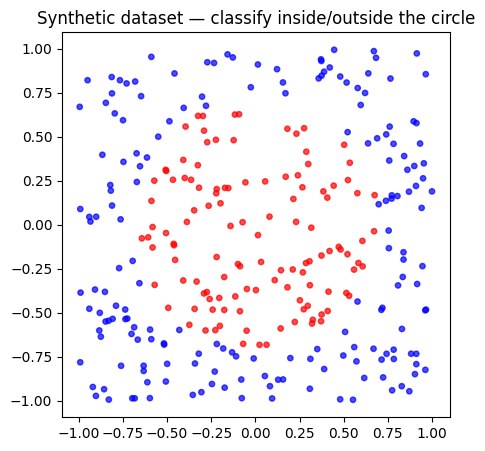

In [3]:
torch.manual_seed(42)

N = 300

X = torch.rand(N, 2) * 2 - 1
y = (torch.norm(X, dim=1) < 0.7).float()

X = X.to(device)
y = y.to(device)

print(f"X: {X.shape}  on {X.device}")
print(f"y: {y.shape}  on {y.device}")
print(f"Class balance — inside: {y.sum().int()}, outside: {(y==0).sum().int()}")

# ── convert to numpy for matplotlib ──────────────────────────────────────
# PyTorch's .numpy() bridge can be broken when torch and numpy are mismatched.
# Workaround: go through Python lists first — always works regardless of build.
#   .detach() — drop gradient info
#   .cpu()    — move to RAM
#   .tolist() — convert to plain Python list (no torch-numpy bridge needed)
# Then wrap in np.array() to get a regular numpy array for matplotlib.
import numpy as np

X_np = np.array(X.detach().cpu().tolist())   # shape (300, 2)
y_np = np.array(y.detach().cpu().tolist())   # shape (300,)

import matplotlib.pyplot as plt
plt.figure(figsize=(5, 5))
plt.scatter(X_np[:, 0], X_np[:, 1], c=y_np, cmap="bwr", s=15, alpha=0.7)
plt.title("Synthetic dataset — classify inside/outside the circle")
plt.axis("equal")
plt.show()

## 2 — Model definition
A minimal 2-layer MLP.  
`Linear → ReLU → Linear → Sigmoid`

In [4]:
class TinyMLP(nn.Module):
    def __init__(self):
        super().__init__()
        # hidden layer: 2 input features → 16 neurons
        self.fc1 = nn.Linear(2, 16)
        # output layer: 16 neurons → 1 probability score
        self.fc2 = nn.Linear(16, 1)
        # ReLU activation adds non-linearity so the model can learn curves
        self.relu = nn.ReLU()
        # Sigmoid squashes output to (0, 1) — interpretable as probability
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.relu(self.fc1(x))        # (N, 2) → (N, 16)
        x = self.sigmoid(self.fc2(x))     # (N, 16) → (N, 1)
        return x.squeeze(1)               # (N, 1) → (N,)  remove trailing dim


# ── move model weights onto the selected device ───────────────────────────
# All learnable parameters (weights & biases) are copied to the device.
# The model and input data MUST be on the same device or PyTorch will error.
model = TinyMLP().to(device)

print(model)
print(f"\nModel device : {next(model.parameters()).device}")
total_params = sum(p.numel() for p in model.parameters())
print(f"Total trainable parameters: {total_params}")

TinyMLP(
  (fc1): Linear(in_features=2, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=1, bias=True)
  (relu): ReLU()
  (sigmoid): Sigmoid()
)

Model device : mps:0
Total trainable parameters: 65


## 3 — Loss function & optimizer

In [5]:
# Binary Cross-Entropy: standard loss for binary classification.
# Penalises the model heavily when it is confidently wrong.
criterion = nn.BCELoss()

# Adam optimizer: maintains a per-parameter adaptive learning rate.
# lr=0.01 means we move weights by ~1% of the gradient each step.
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

## 4 — The training loop ⬅️ core focus

In [6]:
EPOCHS    = 100    # one epoch = one full pass through the training data
BATCH_SIZE = 32    # number of samples processed before each weight update

loss_history = []  # track loss per epoch so we can plot it later

# ── outer loop: repeat over the whole dataset multiple times ──────────────
for epoch in range(EPOCHS):

    # shuffle indices each epoch so batches are different every time
    # avoids the model memorising the order of samples
    perm = torch.randperm(N)              # random permutation of [0, N)
    X_shuffled = X[perm]                  # reorder inputs
    y_shuffled = y[perm]                  # reorder labels (same permutation!)

    epoch_loss = 0.0                      # accumulate loss across batches

    # ── inner loop: iterate over mini-batches ─────────────────────────────
    for i in range(0, N, BATCH_SIZE):     # step through data in chunks

        x_batch = X_shuffled[i : i + BATCH_SIZE]   # slice one batch of inputs
        y_batch = y_shuffled[i : i + BATCH_SIZE]   # slice matching labels

        # ── STEP 1: FORWARD PASS ─────────────────────────────────────────
        # Run inputs through the model to produce predictions.
        # PyTorch records every operation here to build the computation graph
        # (needed for backprop in the next step).
        preds = model(x_batch)            # shape: (batch_size,)  values in (0,1)

        # ── STEP 2: COMPUTE LOSS ─────────────────────────────────────────
        # Compare predictions to ground-truth labels.
        # Returns a single scalar — the average error across the batch.
        loss = criterion(preds, y_batch)

        # ── STEP 3: BACKWARD PASS (backpropagation) ───────────────────────
        # Walk the computation graph backwards and compute d(loss)/d(weight)
        # for every parameter. Gradients are stored inside each parameter tensor
        # at param.grad.
        loss.backward()

        # ── STEP 4: OPTIMIZER STEP ────────────────────────────────────────
        # Use the gradients computed above to nudge every weight in the
        # direction that reduces the loss.
        # Adam: weight = weight - lr * adaptive_grad
        optimizer.step()

        # ── STEP 5: ZERO THE GRADIENTS ────────────────────────────────────
        # Gradients ACCUMULATE by default in PyTorch (+=).
        # We must reset them to zero before the next batch, otherwise
        # they'll add onto the previous batch's gradients.
        optimizer.zero_grad()

        epoch_loss += loss.item()         # .item() extracts scalar from tensor

    # average loss over all batches in this epoch
    avg_loss = epoch_loss / (N / BATCH_SIZE)
    loss_history.append(avg_loss)

    if (epoch + 1) % 10 == 0:            # print progress every 10 epochs
        print(f"Epoch {epoch+1:3d}/{EPOCHS}  loss={avg_loss:.4f}")

Epoch  10/100  loss=0.5120
Epoch  20/100  loss=0.3009
Epoch  30/100  loss=0.2015
Epoch  40/100  loss=0.1559
Epoch  50/100  loss=0.1290
Epoch  60/100  loss=0.1071
Epoch  70/100  loss=0.0933
Epoch  80/100  loss=0.0940
Epoch  90/100  loss=0.0764
Epoch 100/100  loss=0.0692


## 5 — Evaluate & visualise

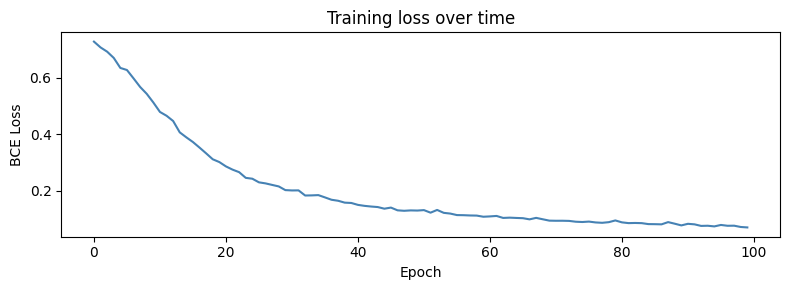

Running on : mps
Final accuracy: 99.3%


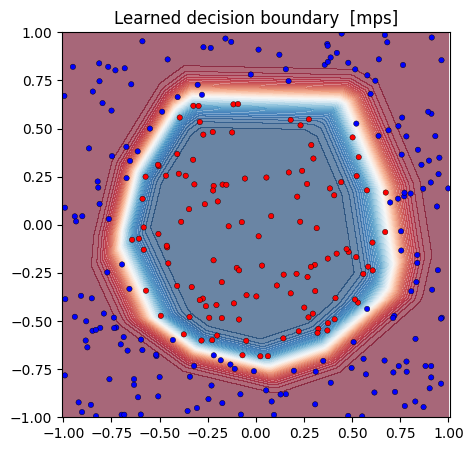

In [7]:
import numpy as np

# ── loss curve ────────────────────────────────────────────────────────────
plt.figure(figsize=(8, 3))
plt.plot(loss_history, color="steelblue")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training loss over time")
plt.tight_layout()
plt.show()

# ── accuracy ─────────────────────────────────────────────────────────────
with torch.no_grad():
    all_preds = model(X)
    predicted_labels = (all_preds > 0.5).float()
    accuracy = (predicted_labels == y).float().mean()
    print(f"Running on : {device}")
    print(f"Final accuracy: {accuracy * 100:.1f}%")

# ── decision boundary ─────────────────────────────────────────────────────
grid_range = torch.linspace(-1, 1, 200)
gx, gy = torch.meshgrid(grid_range, grid_range, indexing="ij")
grid_points = torch.stack([gx.flatten(), gy.flatten()], dim=1).to(device)

with torch.no_grad():
    grid_preds = model(grid_points).reshape(200, 200)

# same tolist() workaround — avoids the broken torch→numpy bridge
gx_np         = np.array(gx.tolist())
gy_np         = np.array(gy.tolist())
grid_preds_np = np.array(grid_preds.detach().cpu().tolist())

plt.figure(figsize=(5, 5))
plt.contourf(gx_np, gy_np, grid_preds_np, levels=50, cmap="RdBu", alpha=0.6)
plt.scatter(X_np[:, 0], X_np[:, 1], c=y_np, cmap="bwr", s=15, edgecolors="k", linewidths=0.3)
plt.title(f"Learned decision boundary  [{device}]")
plt.axis("equal")
plt.show()

## Cheat sheet — the 5 steps every training loop needs

```python
preds = model(x)            # 1. FORWARD   — compute predictions
loss  = criterion(preds, y) # 2. LOSS    — measure error
loss.backward()             # 3. BACKWARD  — compute gradients
optimizer.step()            # 4. STEP      — update weights
optimizer.zero_grad()       # 5. ZERO GRAD — reset for next batch
```

| Step | What it does | Key concept |
|---|---|---|
| Forward | Multiply inputs through layers | Computation graph built |
| Loss | Single number measuring wrongness | Lower = better |
| Backward | Chain rule from loss → every weight | Gradients = slopes |
| Step | `w = w - lr * grad` | Gradient descent |
| Zero grad | Clear `.grad` buffers | Prevents accumulation |